# CleanRoute Astana — a mini air-quality adviser for outdoor travel
**Final Project — AI Fundamentals** · Student: Ibragim Mukash

One pipeline, four course algorithms, one goal: on a smoggy Astana winter evening, should a resident **leave now or wait**, and **which way** should they walk?

| # | Algorithm | Module | Subproblem |
|---|---|---|---|
| 1 | Bayesian inference | 6 | noisy sensor reading → belief `P(H)` |
| 2 | A* search (vs BFS/UCS) | 2–4 | 6×6 map → minimum-exposure route |
| 3 | MDP | 5 | belief + route dose → *Go* / *Wait* |
| 4 | HMM (Viterbi + forward) | 7 | reading sequence → better belief |

All inputs are **hypothetical** (the guidelines allow predefined probabilities, transitions, rewards and toy maps). Arithmetic uses exact `Fraction`.

## Setup and assumptions

In [1]:
from fractions import Fraction as F
import heapq
from collections import deque

# --- hidden states and the noisy home sensor (Module 6) ---
STATES    = ("A", "H")      # A = acceptable air, H = hazardous air
PRIOR_H   = F(3, 10)        # P(H) before any reading
P_ALARM_H = F(17, 20)       # sensitivity   P(alarm | H)
P_ALARM_A = F(1, 5)         # false alarm   P(alarm | A)

# --- hourly air-quality chain (transition model) ---
TRANS = {"A": {"A": F(7, 10), "H": F(3, 10)},
         "H": {"A": F(2, 5),  "H": F(3, 5)}}

# --- reward model (Module 5) ---
GAMMA   = F(9, 10)
R_WAIT  = {"A": -4, "H": -6}
BENEFIT = F(12)             # utility of arriving on time
DOSE_K  = F(1, 50)          # dose-cost coefficient
CONC    = {"A": 15, "H": 75}  # ug/m3 per weight unit, per state

# --- 6x6 block map (Modules 2-4): 1 park ... 5 busy avenue, None = impassable
GRID = [
    [1, 1, 1, 1, 1, 1],
    [1, None, None, 4, 4, 4],
    [1, None, None, 4, 5, 4],
    [1, 1, 1, 4, 5, 4],
    [None, None, 1, 4, 5, 4],
    [None, None, 2, 4, 4, 4],
]
START, GOAL = (5, 2), (0, 5)
MIN_W = 1
NEIGH = ((-1, 0), (0, 1), (1, 0), (0, -1))

print("prior P(H)          =", PRIOR_H, "=", float(PRIOR_H))
print("P(alarm|H), P(alarm|A) =", P_ALARM_H, ",", P_ALARM_A)
print("No real dataset and no trained model are used.")

prior P(H)          = 3/10 = 0.3
P(alarm|H), P(alarm|A) = 17/20 , 1/5
No real dataset and no trained model are used.


## Task 1 — Bayesian inference: one noisy reading → belief

In [2]:
EMISSION = {"alarm": {"H": P_ALARM_H, "A": P_ALARM_A},
            "calm":  {"H": 1 - P_ALARM_H, "A": 1 - P_ALARM_A}}

def bayes(obs, prior=PRIOR_H):
    """Exact Bayes update. Returns (joint_H, joint_A, evidence, posterior_H)."""
    jH = EMISSION[obs]["H"] * prior
    jA = EMISSION[obs]["A"] * (1 - prior)
    ev = jH + jA
    return jH, jA, ev, jH / ev

for obs in ("alarm", "calm"):
    jH, jA, ev, post = bayes(obs)
    print(f"--- observation e = {obs!r} ---")
    print(f"  P(e,H) = {jH}    P(e,A) = {jA}")
    print(f"  P(e)   = {jH} + {jA} = {ev}")
    print(f"  P(H|e) = {jH} / {ev} = {post} = {float(post):.4f} = {float(post):.1%}")
    assert abs(float(post) + float(jA / ev) - 1) < 1e-12

LR = P_ALARM_H / P_ALARM_A
print("likelihood ratio P(alarm|H)/P(alarm|A) =", LR, "=", float(LR))
BELIEF_ALARM = bayes("alarm")[3]

--- observation e = 'alarm' ---
  P(e,H) = 51/200    P(e,A) = 7/50
  P(e)   = 51/200 + 7/50 = 79/200
  P(H|e) = 51/200 / 79/200 = 51/79 = 0.6456 = 64.6%
--- observation e = 'calm' ---
  P(e,H) = 9/200    P(e,A) = 14/25
  P(e)   = 9/200 + 14/25 = 121/200
  P(H|e) = 9/200 / 121/200 = 9/121 = 0.0744 = 7.4%
likelihood ratio P(alarm|H)/P(alarm|A) = 17/4 = 4.25


### Interpretation
One `alarm` multiplies the odds of hazardous air by 4.25 and lifts `P(H)` from 30% to 64.6%; a `calm` reading drops it to 7.4%. The raw signal is therefore useless on its own — only the posterior is a valid input to the decision.

## Task 2 — Search on the weighted grid: which way to walk

In [3]:
def neighbours(cell):
    r, c = cell
    for dr, dc in NEIGH:
        nr, nc = r + dr, c + dc
        if 0 <= nr < 6 and 0 <= nc < 6 and GRID[nr][nc] is not None:
            yield (nr, nc)

def route_weight(route):
    return sum(GRID[r][c] for r, c in route)

def _reconstruct(came, cur):
    path = [cur]
    while cur in came:
        cur = came[cur]
        path.append(cur)
    path.reverse()
    return path

def bfs():
    frontier = deque([START]); came = {}; seen = {START}; expanded = 0
    while frontier:
        cur = frontier.popleft(); expanded += 1
        if cur == GOAL:
            return _reconstruct(came, cur), expanded
        for nxt in neighbours(cur):
            if nxt not in seen:
                seen.add(nxt); came[nxt] = cur; frontier.append(nxt)
    return None, expanded

def best_first(use_heuristic):
    def h(cell):
        r, c = cell; gr, gc = GOAL
        return (abs(r - gr) + abs(c - gc)) * MIN_W   # admissible + consistent
    g = {START: GRID[START[0]][START[1]]}
    came = {}; closed = set(); counter = 0
    h0 = h(START) if use_heuristic else 0
    heap = [(g[START] + h0, h0, counter, START)]
    expanded = 0
    while heap:
        f, hv, _, cur = heapq.heappop(heap)
        if cur in closed:
            continue
        closed.add(cur); expanded += 1
        if cur == GOAL:
            return _reconstruct(came, cur), g[GOAL], expanded
        for nxt in neighbours(cur):
            if nxt in closed:
                continue
            t = g[cur] + GRID[nxt[0]][nxt[1]]
            if t < g.get(nxt, float("inf")):
                g[nxt] = t; came[nxt] = cur; counter += 1
                hn = h(nxt) if use_heuristic else 0
                heapq.heappush(heap, (t + hn, hn, counter, nxt))
    return None, None, expanded

bfs_route, bfs_exp = bfs()
bfs_steps = len(bfs_route) - 1
ucs_route, ucs_w, ucs_exp = best_first(False)
ast_route, ast_w, ast_exp = best_first(True)

print("BFS  steps", bfs_steps, " weight", route_weight(bfs_route), " expanded", bfs_exp)
print("UCS  steps", len(ucs_route) - 1, " weight", ucs_w, " expanded", ucs_exp)
print("A*   steps", len(ast_route) - 1, " weight", ast_w, " expanded", ast_exp)
assert ucs_w == ast_w == route_weight(ucs_route)   # A* keeps the UCS optimum
assert ast_exp < ucs_exp                           # ... while expanding fewer nodes
W_SHORT, W_STAR = route_weight(bfs_route), ast_w
print("dose reduction by A*:", W_SHORT - W_STAR, "units =",
      f"{(W_SHORT - W_STAR) / W_SHORT:.1%}", "for", len(ast_route) - 1 - bfs_steps,
      "extra steps")

BFS  steps 8  weight 19  expanded 27
UCS  steps 12  weight 14  expanded 21
A*   steps 12  weight 14  expanded 16
dose reduction by A*: 5 units = 26.3% for 4 extra steps


### Interpretation
BFS minimises *steps* (8) but walks through busy blocks (weight 19). UCS and A* minimise *exposure* (weight 14, 12 steps); A* reaches the same optimum while expanding 16 nodes instead of 21, because the Manhattan heuristic is admissible.

## Task 3 — MDP: turn belief + route dose into an action

In [4]:
def r_go(state, W):
    return BENEFIT - DOSE_K * CONC[state] * W

def decide(pH, W):
    pA = 1 - pH
    q_go   = pA * r_go("A", W) + pH * r_go("H", W)
    q_wait = pA * R_WAIT["A"]  + pH * R_WAIT["H"]
    dA = r_go("A", W) - R_WAIT["A"]
    dH = r_go("H", W) - R_WAIT["H"]
    return q_go, q_wait, dA / (dA - dH)

print("=== one reading 'alarm', P(H) =", BELIEF_ALARM, "===")
for label, W in (("shortest (BFS)", W_SHORT), ("A* min-exposure", W_STAR)):
    q_go, q_wait, thr = decide(BELIEF_ALARM, W)
    act = "Go" if q_go >= q_wait else "Wait"
    print(f"  {label:16s} W={W:2d}  Q(Go)={float(q_go):+.4f}  Q(Wait)={float(q_wait):+.4f}"
          f"  p*={float(thr):.2%}  -> {act}")

def value_iteration(W, iters=300):
    V = {s: F(0) for s in STATES}
    for it in range(1, iters + 1):
        newV = {s: max(r_go(s, W),
                       R_WAIT[s] + GAMMA * sum(TRANS[s][t] * V[t] for t in STATES))
                for s in STATES}
        if all(abs(float(newV[s] - V[s])) < 1e-9 for s in STATES):
            return newV, it
        V = newV
    return V, iters

print("\n=== value iteration, gamma =", GAMMA, "===")
for label, W in (("shortest", W_SHORT), ("A*", W_STAR)):
    V, it = value_iteration(W)
    print(f"  {label:9s} W={W:2d}  V(A)={float(V['A']):+.4f}  V(H)={float(V['H']):+.4f}"
          f"  iterations={it}")

=== one reading 'alarm', P(H) = 51/79 ===
  shortest (BFS)   W=19  Q(Go)=-8.4190  Q(Wait)=-5.2911  p*=49.52%  -> Wait
  A* min-exposure  W=14  Q(Go)=-3.0456  Q(Wait)=-5.2911  p*=79.73%  -> Go

=== value iteration, gamma = 9/10 ===
  shortest  W=19  V(A)=+6.3000  V(H)=-8.1130  iterations=36
  A*        W=14  V(A)=+7.8000  V(H)=-6.9391  iterations=35


### Interpretation
With one `alarm` the *shortest* route says **Wait** (p\* = 49.5% < 64.6%) while the *A\** route says **Go** (p\* = 79.7% > 64.6%): same belief, different route, opposite advice. Value iteration converges to the same stationary policy (Go in A, Wait in H) and shows the cleaner route raises V(A) from +6.30 to +7.80.

## Task 4 — HMM: three readings → a better belief

In [5]:
INIT = {"A": 1 - PRIOR_H, "H": PRIOR_H}
OBS  = ("alarm", "alarm", "calm")

def viterbi(obs):
    delta = {s: INIT[s] * EMISSION[obs[0]][s] for s in STATES}
    psi = []
    for o in obs[1:]:
        step, new = {}, {}
        for s in STATES:
            best, arg = max(((delta[p] * TRANS[p][s], p) for p in STATES))
            new[s] = best * EMISSION[o][s]
            step[s] = arg
        delta = new
        psi.append(step)
    seq = [max(STATES, key=lambda s: delta[s])]
    for t in range(len(obs) - 1, 0, -1):
        seq.append(psi[t - 1][seq[-1]])
    return list(reversed(seq))

def forward(obs):
    alpha = {s: INIT[s] * EMISSION[obs[0]][s] for s in STATES}
    beliefs = [alpha["H"] / sum(alpha.values())]
    for o in obs[1:]:
        alpha = {s: EMISSION[o][s] * sum(alpha[p] * TRANS[p][s] for p in STATES)
                 for s in STATES}
        beliefs.append(alpha["H"] / sum(alpha.values()))
    return beliefs

SEQ = viterbi(OBS)
BEL = forward(OBS)
print("Viterbi hidden sequence      :", SEQ)
print("forward P(H) after 1/2/3 read:", [f"{float(b):.1%}" for b in BEL])
assert BEL[0] == BELIEF_ALARM          # filtering agrees with Task 1 on one reading
FINAL_BELIEF = BEL[-1]

Viterbi hidden sequence      : ['H', 'H', 'A']
forward P(H) after 1/2/3 read: ['64.6%', '80.6%', '18.1%']


### Interpretation
Viterbi reads the sequence as `H, H, A` — two hazardous hours then a clean one — and forward filtering drops `P(H)` to 18.1%. The third `calm` reading, combined with the transition model, is what makes leaving safe.

## Integration — the final recommendation

In [6]:
print("belief used :", f"P(H) = {float(FINAL_BELIEF):.1%} (HMM forward, 3 readings)")
for label, W in (("shortest (BFS)", W_SHORT), ("A* min-exposure", W_STAR)):
    q_go, q_wait, thr = decide(FINAL_BELIEF, W)
    act = "Go" if q_go >= q_wait else "Wait"
    print(f"  {label:16s} W={W:2d}  Q(Go)={float(q_go):+.4f}  p*={float(thr):.2%}  -> {act}")

q_go, q_wait, thr = decide(FINAL_BELIEF, W_STAR)
action = "Go" if q_go >= q_wait else "Wait"
print("\nFINAL RECOMMENDATION:", action, "via the A* route;",
      f"P(H) = {float(FINAL_BELIEF):.1%} < p* = {float(thr):.1%}")
print("margin Q(Go) - Q(Wait) =", f"{float(q_go - q_wait):+.3f}", "utility points")

belief used : P(H) = 18.1% (HMM forward, 3 readings)
  shortest (BFS)   W=19  Q(Go)=+2.1640  p*=49.52%  -> Go
  A* min-exposure  W=14  Q(Go)=+4.7525  p*=79.73%  -> Go

FINAL RECOMMENDATION: Go via the A* route; P(H) = 18.1% < p* = 79.7%
margin Q(Go) - Q(Wait) = +9.115 utility points


## Visualisation — the map and the decision thresholds

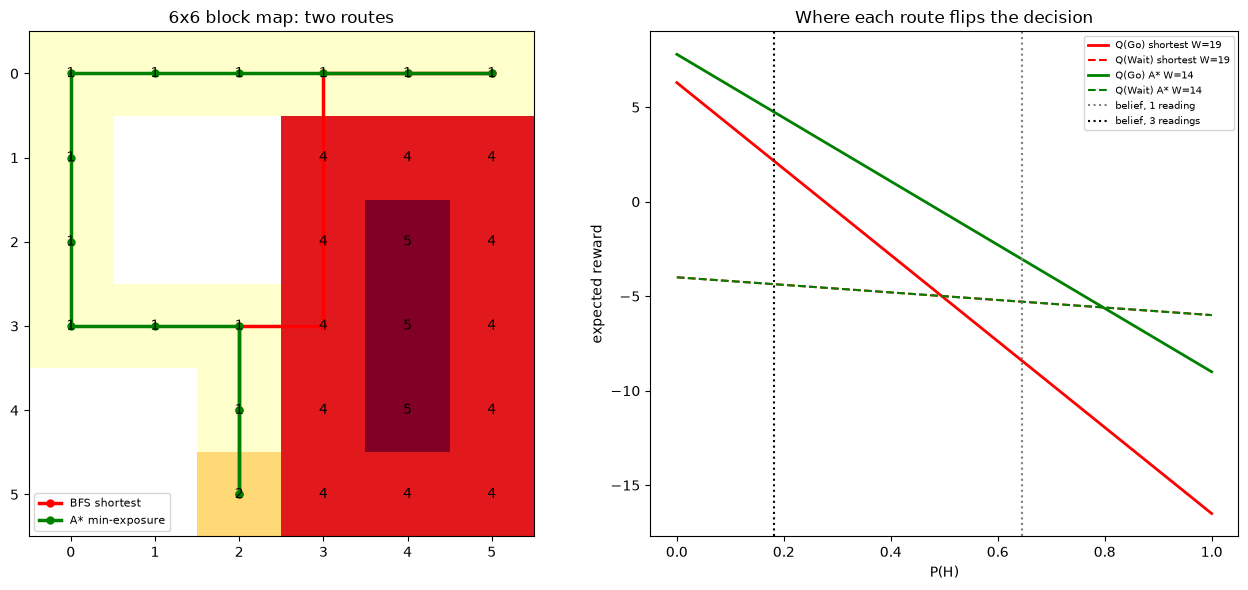

In [7]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

ax = axes[0]
W = np.array([[GRID[r][c] if GRID[r][c] is not None else np.nan for c in range(6)]
              for r in range(6)])
ax.imshow(W, cmap="YlOrRd", vmin=1, vmax=5)
for r in range(6):
    for c in range(6):
        if GRID[r][c] is None:
            ax.text(c, r, "#", ha="center", va="center", color="white",
                    fontsize=12, weight="bold")
        else:
            ax.text(c, r, str(GRID[r][c]), ha="center", va="center",
                    color="black", fontsize=10)
for route, color, label in ((bfs_route, "red", "BFS shortest"),
                            (ast_route, "green", "A* min-exposure")):
    ys = [p[0] for p in route]; xs = [p[1] for p in route]
    ax.plot(xs, ys, color=color, lw=2.5, marker="o", ms=5, label=label)
ax.set_xticks(range(6)); ax.set_yticks(range(6))
ax.set_title("6x6 block map: two routes")
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]
ps = [i / 100 for i in range(0, 101)]
for Wt, color, label in ((W_SHORT, "red", "shortest W=19"), (W_STAR, "green", "A* W=14")):
    q_go = [float((1 - p) * r_go("A", Wt) + p * r_go("H", Wt)) for p in ps]
    q_wait = [float((1 - p) * R_WAIT["A"] + p * R_WAIT["H"]) for p in ps]
    ax.plot(ps, q_go, color=color, lw=2, label=f"Q(Go) {label}")
    ax.plot(ps, q_wait, color=color, lw=1.5, ls="--", label=f"Q(Wait) {label}")
ax.axvline(float(BELIEF_ALARM), color="grey", ls=":", label="belief, 1 reading")
ax.axvline(float(FINAL_BELIEF), color="black", ls=":", label="belief, 3 readings")
ax.set_xlabel("P(H)"); ax.set_ylabel("expected reward")
ax.set_title("Where each route flips the decision")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## Summary of results

In [8]:
import pandas as pd

rows = [
    ("1", "Bayes, one reading 'alarm'", f"P(H) = {BELIEF_ALARM} = {float(BELIEF_ALARM):.1%}"),
    ("2", "BFS fewest steps", f"{bfs_steps} steps, weight {W_SHORT}"),
    ("2b", "A* minimum exposure", f"{len(ast_route)-1} steps, weight {W_STAR}"),
    ("2c", "Dose reduction by A*", f"{W_SHORT-W_STAR} units, {(W_SHORT-W_STAR)/W_SHORT:.1%}"),
    ("3", "MDP, 1 reading + shortest", "Wait (p* = 49.5%)"),
    ("3b", "MDP, 1 reading + A*", "Go (p* = 79.7%)"),
    ("4", "Viterbi, 3 readings", str(SEQ)),
    ("4b", "Forward filtering", f"P(H) -> {float(BEL[-1]):.1%}"),
    ("FINAL", "Recommendation", f"{action}, A* route"),
]
pd.DataFrame(rows, columns=["#", "result", "value"]).set_index("#")

,result,value
#,,
1,"Bayes, one reading 'alarm'",P(H) = 51/79 = 64.6%
2,BFS fewest steps,"8 steps, weight 19"
2b,A* minimum exposure,"12 steps, weight 14"
2c,Dose reduction by A*,"5 units, 26.3%"
3,"MDP, 1 reading + shortest",Wait (p* = 49.5%)
3b,"MDP, 1 reading + A*",Go (p* = 79.7%)
4,"Viterbi, 3 readings","['H', 'H', 'A']"
4b,Forward filtering,P(H) -> 18.1%
FINAL,Recommendation,"Go, A* route"


## Conclusion
The four algorithms form one system: Bayes converts a noisy reading into a belief, A* converts the map into a dose, the MDP converts belief + dose into an action, and the HMM refines the belief from a *sequence* of readings. Each hand-off changes the recommendation, which is exactly the integration the assignment asks for.

**Limitations & future work:** calibrate the sensor and transition model from real AQI data; learn the policy with Q-learning; add effort-dependent exposure and a finite deadline; expose the pipeline as an API.

*AI-assisted code disclosure:* developed with an AI coding assistant; every derived value is checked against exact hand-computed fractions (asserts above).